# ToolNode

https://docs.langchain.com/oss/python/langgraph/workflows-agents#toolnode


https://docs.langchain.com/oss/python/langgraph/workflows-agents#agents


## 

# 세팅  

In [1]:
# Load environment variables in a file called .env
# API 키 설정 
import os
from dotenv import load_dotenv
load_dotenv(override=True)

True

# Lab 1-1 :  ToolNode




In [ ]:
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import MessagesState, StateGraph, START, END


@tool
def search(query: str) -> str:
    """Search for information."""
    return f"Results for: {query}"


@tool
def calculator(expression: str) -> str:
    """Evaluate a math expression."""
    return str(eval(expression))


In [8]:
# 그래프에서 사용할 도구 목록
tools = [search, calculator]

# LLM 생성 후 도구 스키마를 바인딩
# bind_tools는 도구를 실행하지 않고, 모델이 tool_calls를 생성할 수 있게 스키마만 전달
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)
llm_with_tools = llm.bind_tools(tools)


def agent(state: MessagesState) -> dict:
    """현재까지의 메시지 전체를 LLM에 전달하고 응답 AIMessage를 반환"""
    # 반환값의 messages는 MessagesState의 add_messages 리듀서에 의해 기존 목록에 누적됨
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


In [9]:
builder = StateGraph(MessagesState)

# agent 노드: LLM 호출 담당
builder.add_node("agent", agent)

# tools 노드: 마지막 AIMessage의 tool_calls를 읽어 실제 함수를 실행하고 ToolMessage로 반환
builder.add_node("tools", ToolNode(tools))

# 시작 지점은 항상 agent
builder.add_edge(START, "agent")

# tools_condition: 마지막 메시지에 tool_calls가 있으면 "tools", 없으면 END로 라우팅
builder.add_conditional_edges(
    "agent",
    tools_condition,
    {"tools": "tools", END: END},
)

# 도구 실행 결과를 다시 agent로 보내 최종 답변을 생성 (ReAct 루프)
builder.add_edge("tools", "agent")

graph = builder.compile()


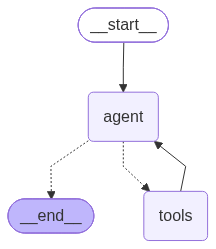

In [10]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "123 * 456 + 789 를 계산해줘"}]}
    )
for message in result["messages"]:
    message.pretty_print()

print("\n" + "=" * 50 + "\n")


================================ Human Message =================================

123 * 456 + 789 를 계산해줘
================================== Ai Message ==================================
Tool Calls:
  calculator (call_vYC5D8JnVNknF1fLU24iH8Ay)
 Call ID: call_vYC5D8JnVNknF1fLU24iH8Ay
  Args:
    expression: 123 * 456 + 789
================================= Tool Message =================================
Name: calculator

56877
================================== Ai Message ==================================

123 × 456 = 56,088  
56,088 + 789 = 56,877

결과: 56,877




In [12]:
# 검색 도구가 호출되는 예시
result = graph.invoke(
    {"messages": [{"role": "user", "content": "LangGraph 최신 소식을 검색해줘"}]}
    )
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

LangGraph 최신 소식을 검색해줘
================================== Ai Message ==================================
Tool Calls:
  search (call_TpYF0L2BcvVufT36xHNmsWrc)
 Call ID: call_TpYF0L2BcvVufT36xHNmsWrc
  Args:
    query: LangGraph 최신 소식
================================= Tool Message =================================
Name: search

Results for: LangGraph 최신 소식
================================== Ai Message ==================================
Tool Calls:
  search (call_Xu0aSSMwAvcMPxbAnXiGj6vP)
 Call ID: call_Xu0aSSMwAvcMPxbAnXiGj6vP
  Args:
    query: LangGraph news 2026
    time: 2026-01-01..2026-08-18
================================= Tool Message =================================
Name: search

Results for: LangGraph news 2026
================================== Ai Message ==================================
Tool Calls:
  search (call_ItyUvH0lEdfaNN31xTNChpKL)
 Call ID: call_ItyUvH0lEdfaNN31xTNChpKL
  Args:
    que

# Lab 1-2 : 직접 호출




In [13]:
from langchain.tools import tool
from langchain_core.messages import ToolMessage
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import tools_condition
from langgraph.graph import MessagesState, StateGraph, START, END



@tool
def search(query: str) -> str:
    """Search for information."""
    return f"Results for: {query}"


@tool
def calculator(expression: str) -> str:
    """Evaluate a math expression."""
    return str(eval(expression))


# 그래프에서 사용할 도구 목록
tools = [search, calculator]

# 도구 이름으로 도구 객체를 찾기 위한 딕셔너리
tools_by_name = {t.name: t for t in tools}

# LLM 생성 후 도구 스키마를 바인딩
# bind_tools는 도구를 실행하지 않고, 모델이 tool_calls를 생성할 수 있게 스키마만 전달
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)
llm_with_tools = llm.bind_tools(tools)


def agent(state: MessagesState) -> dict:
    """현재까지의 메시지 전체를 LLM에 전달하고 응답 AIMessage를 반환"""
    # 반환값의 messages는 MessagesState의 add_messages 리듀서에 의해 기존 목록에 누적됨
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


def tool_node(state: MessagesState) -> dict:
    """마지막 AIMessage의 tool_calls를 순회하며 도구를 실행하고 ToolMessage 목록을 반환"""
    # 직전 메시지가 tool_calls를 담고 있는 AIMessage
    last_message = state["messages"][-1]

    outputs = []
    # 한 번의 응답에 여러 tool_calls가 들어올 수 있으므로 전부 순회
    for tool_call in last_message.tool_calls:
        # tool_call은 {"name": ..., "args": {...}, "id": ..., "type": "tool_call"} 형태
        selected_tool = tools_by_name[tool_call["name"]]

        try:
            # args 딕셔너리를 그대로 invoke에 전달
            result = selected_tool.invoke(tool_call["args"])
        except Exception as e:
            # 예외를 문자열로 변환해 LLM이 재시도할 수 있도록 전달
            result = f"Error: {repr(e)}"

        # tool_call_id는 반드시 원본 tool_call의 id와 일치해야 함
        outputs.append(
            ToolMessage(
                content=str(result),
                name=tool_call["name"],
                tool_call_id=tool_call["id"],
            )
        )

    return {"messages": outputs}


builder = StateGraph(MessagesState)

# agent 노드: LLM 호출 담당
builder.add_node("agent", agent)

# tools 노드: 직접 구현한 tool_node 함수 사용
builder.add_node("tools", tool_node)

# 시작 지점은 항상 agent
builder.add_edge(START, "agent")

# tools_condition: 마지막 메시지에 tool_calls가 있으면 "tools", 없으면 END로 라우팅
builder.add_conditional_edges(
    "agent",
    tools_condition,
    {"tools": "tools", END: END},
)

# 도구 실행 결과를 다시 agent로 보내 최종 답변을 생성 (ReAct 루프)
builder.add_edge("tools", "agent")

graph = builder.compile()


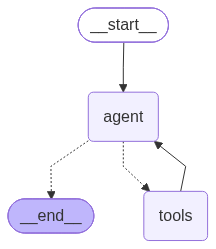

In [14]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
result = graph.invoke(
        {"messages": [{"role": "user", "content": "123 * 456 + 789 를 계산해줘"}]}
    )
for message in result["messages"]:
        message.pretty_print()

print("\n" + "=" * 50 + "\n")


================================ Human Message =================================

123 * 456 + 789 를 계산해줘
================================== Ai Message ==================================

계산하면 다음과 같습니다.

123 × 456 = 56,088  
56,088 + 789 = 56,877

따라서 결과는 56,877입니다.




In [ ]:

# 검색 도구가 호출되는 예시
result = graph.invoke(
    {"messages": [{"role": "user", "content": "LangGraph 최신 소식을 검색해줘"}]}
)
for message in result["messages"]:
    message.pretty_print()

# Lab 2-1: 직접 호출  






In [16]:
from langchain.tools import tool

# bind_tools는 도구를 실행하지 않고, 모델이 tool_calls를 생성할 수 있게 스키마만 전달
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

# 도구 정의
@tool
def multiply(a: int, b: int) -> int:
    """`a`와 `b`를 곱합니다.

    Args:
        a: 첫 번째 정수
        b: 두 번째 정수
    """
    # @tool 데코레이터가 함수를 BaseTool 객체로 변환
    # 함수 이름 -> 도구 이름, docstring -> 도구 설명, 타입 힌트 -> 인자 스키마로 사용됨
    return a * b


@tool
def add(a: int, b: int) -> int:
    """`a`와 `b`를 더합니다.

    Args:
        a: 첫 번째 정수
        b: 두 번째 정수
    """
    return a + b


@tool
def divide(a: int, b: int) -> float:
    """`a`를 `b`로 나눕니다.

    Args:
        a: 첫 번째 정수
        b: 두 번째 정수
    """
    return a / b


# LLM에 도구를 결합
tools = [add, multiply, divide]
# 도구 이름을 키로 하는 딕셔너리 — tool_node에서 tool_call["name"]으로 도구를 찾을 때 사용
tools_by_name = {t.name: t for t in tools}
# bind_tools()로 도구 스키마를 LLM에 전달 (실제 실행이 아니라 호출 가능 목록을 알려주는 것)
llm_with_tools = llm.bind_tools(tools)

In [17]:
from typing import Literal
from IPython.display import Image, display
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain.messages import SystemMessage, HumanMessage, ToolMessage


# 노드 정의
def llm_call(state: MessagesState):
    """LLM이 도구를 호출할지 말지 결정하는 노드"""
    return {
        # 반환한 메시지는 MessagesState의 add_messages 리듀서에 의해 기존 목록에 누적됨
        "messages": [
            # bind_tools()로 도구가 바인딩된 LLM 호출
            llm_with_tools.invoke(
                [
                    # 매 호출마다 시스템 메시지를 맨 앞에 붙임 (상태에는 저장되지 않음)
                    SystemMessage(
                        content="당신은 주어진 입력값들에 대해 산술 연산을 수행하는 유능한 어시스턴트입니다."
                    )
                ]
                # 지금까지 누적된 대화 기록(HumanMessage, AIMessage, ToolMessage 등)을 뒤에 이어 붙임
                + state["messages"]
            )
        ]
    }


def tool_node(state: MessagesState):
    """LLM이 요청한 도구를 실제로 실행하는 노드"""
    result = []
    # 가장 최근 메시지(AIMessage)의 tool_calls 목록을 순회
    # tool_calls는 한 번에 여러 개가 올 수 있으므로 반복문으로 처리
    for tool_call in state["messages"][-1].tool_calls:
        # 도구 이름으로 실제 도구 객체를 조회
        tool = tools_by_name[tool_call["name"]]
        # LLM이 생성한 인자(args)를 넣어 도구를 실행하고 결과를 받음
        observation = tool.invoke(tool_call["args"])
        # 실행 결과를 ToolMessage로 감싸며, tool_call_id로 어떤 요청에 대한 응답인지 연결
        result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
    return {"messages": result}


# 도구 노드로 갈지 종료할지 결정하는 조건부 엣지 함수
def should_continue(state: MessagesState) -> Literal["tool_node", END]:
    """LLM이 도구 호출을 했는지 여부에 따라 루프를 계속할지 종료할지 결정"""
    messages = state["messages"]
    last_message = messages[-1]

    # LLM이 도구 호출을 했다면 도구 실행 노드로 이동
    if last_message.tool_calls:
        return "tool_node"
    # 도구 호출이 없으면(최종 답변이면) 그래프 종료
    return END


# 워크플로우 구성
agent_builder = StateGraph(MessagesState)

# 노드 등록
agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("tool_node", tool_node)

# 노드를 연결하는 엣지 추가
agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    # should_continue가 반환할 수 있는 목적지 목록 (그래프 시각화에도 사용됨)
    ["tool_node", END]
)
# 도구 실행 후에는 다시 LLM으로 돌아가 루프를 형성
agent_builder.add_edge("tool_node", "llm_call")

# 에이전트 컴파일
agent = agent_builder.compile()


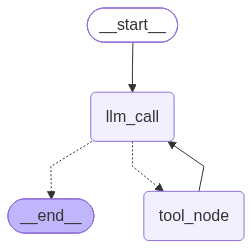

In [18]:

# 에이전트 그래프 시각화 (xray=True는 서브그래프 내부까지 펼쳐서 표시)
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))


In [19]:
# 실행
messages = [HumanMessage(content="3과 4를 더해줘.")]
messages = agent.invoke({"messages": messages})
# 누적된 전체 메시지를 보기 좋게 출력
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

3과 4를 더해줘.
================================== Ai Message ==================================
Tool Calls:
  add (call_rONgNTbMGSzaox464a19R1sN)
 Call ID: call_rONgNTbMGSzaox464a19R1sN
  Args:
    a: 3
    b: 4
================================= Tool Message =================================

7
================================== Ai Message ==================================

3 + 4 = 7


# Lab 2-2: ToolNode

In [20]:
from typing import Literal
from IPython.display import Image, display
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langchain.messages import SystemMessage, HumanMessage


# 노드 정의
def llm_call(state: MessagesState):
    """LLM이 도구를 호출할지 말지 결정하는 노드"""
    return {
        # 반환한 메시지는 MessagesState의 add_messages 리듀서에 의해 기존 목록에 누적됨
        "messages": [
            llm_with_tools.invoke(
                [
                    SystemMessage(
                        content="당신은 주어진 입력값들에 대해 산술 연산을 수행하는 유능한 어시스턴트입니다."
                    )
                ]
                + state["messages"]
            )
        ]
    }


# 워크플로우 구성
agent_builder = StateGraph(MessagesState)

# 노드 등록
agent_builder.add_node("llm_call", llm_call)
# ToolNode: 마지막 AIMessage의 tool_calls를 읽어 해당 도구들을 실행하고
# ToolMessage 목록을 반환하는 프리빌트 노드 (여러 개면 병렬 실행)
# bind_tools()에 넘긴 것과 동일한 tools 리스트를 그대로 전달
agent_builder.add_node("tools", ToolNode(tools))

# 노드를 연결하는 엣지 추가
agent_builder.add_edge(START, "llm_call")
# tools_condition: 마지막 메시지에 tool_calls가 있으면 "tools",
# 없으면 END("__end__")를 반환하는 프리빌트 라우팅 함수
agent_builder.add_conditional_edges(
    "llm_call",
    tools_condition,
    # tools_condition의 반환값 -> 실제 노드 이름 매핑
    {"tools": "tools", END: END},
)
# 도구 실행 후에는 다시 LLM으로 돌아가 루프를 형성
agent_builder.add_edge("tools", "llm_call")

# 에이전트 컴파일
agent = agent_builder.compile()


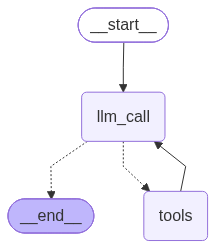

In [21]:

# 에이전트 그래프 시각화
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))


In [22]:

# 실행
messages = [HumanMessage(content="3과 4를 더해줘.")]
messages = agent.invoke({"messages": messages})
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

3과 4를 더해줘.
================================== Ai Message ==================================
Tool Calls:
  add (call_H08xjovzNJx4UFImdV725XfV)
 Call ID: call_H08xjovzNJx4UFImdV725XfV
  Args:
    a: 3
    b: 4
================================= Tool Message =================================
Name: add

7
================================== Ai Message ==================================

3 + 4 = 7
